In [1]:

import seaborn as sns

# Standard libraries
import json
%matplotlib inline
import datetime
import numpy as np
import pandas as pd
import random

import pandas_profiling as pp
import pprint

from matplotlib import pyplot as plt

In [2]:
metadataDf = pd.read_csv('../data/Finalized data parameters_charging.csv')
metadataDf.head()

renames=dict(zip(metadataDf['Gen2/2K'].apply(lambda x: x.lower().replace('.', '_').replace(',','')).tolist(), 
                metadataDf['Unnamed: 1'].apply(lambda x: x.strip().replace(' ', '_').replace(',', '').replace('.', '_')).tolist()))


In [3]:
df = pd.read_csv('../data/gen2k_chd_sample.csv')
df.rename(columns=renames, inplace=True)
df.rename(columns={'charging_history__charge_type__100V_system_200V_systemRapid': 'charge_type'}, inplace=True)

numericalCols = df.select_dtypes(include=[np.number]).columns.tolist()
catCols = list(set(df.columns) -set(numericalCols))
catCols

['charge_type', 'vin']

In [4]:
df.head()

,tcuid,vin,talend_process_time,charging_history__charging_start_date_and_time___year,charging_history__charging_start_date_and_time___month,charging_history__charging_start_date___the_day,charging_history__charging_start_time_date_and_time__,charging_history___charging_start_date_and_time___minute,charging_history__charge Start_date___time_zone,charging_history__Charge_termination_date_and_time___year,...,charging_history__end-of-charge_when_the_battery_average_temperature,charging_history__end-of-charge_when_the_battery_maximum_temperature,charging_history__end-of-charge_when_the_battery_minimum_temperature,Charging_history__Start_charging_when_the_battery_average_cell_voltage,charging_history__Start_charging_when_the_battery_maximum_cell_voltage,charging_history__Start_charging_when_the_battery_minimum_cell_voltage,charging_history__Charging_at_the_end_of_the_current_integration,charging_in_the_charging_history__IGN_minus_OFF_number,charging_history__charging_end_time_IR_sensor_value,charging_history__accessory_information_signal
0,2.047750e+11,1N4AZ1CP7JC301590,2020020100,2020,1,31.0,6.0,43.0,-300,2020,...,12.0,13.0,12.0,3660,3660,3655,11,1,2450,0
1,2.047750e+11,1N4AZ1CP6JC301774,2020020100,2020,1,30.0,17.0,5.0,-300,2020,...,3.0,5.0,2.0,3655,3665,3640,0,3,2450,0
2,2.047750e+11,1N4AZ1CP6JC301774,2020020100,2020,1,30.0,22.0,0.0,-300,2020,...,4.0,6.0,3.0,3695,3700,3680,46,3,2450,0
3,2.047750e+11,1N4AZ1CP6JC301774,2020020100,2020,1,31.0,7.0,31.0,-300,2020,...,2.0,3.0,1.0,4170,4180,4145,0,3,2450,0
4,2.047750e+11,1N4AZ1CP2JC301447,2020020100,2020,1,30.0,17.0,16.0,-360,2020,...,14.0,16.0,13.0,3595,3640,3585,55,1,2450,0


In [5]:
df.describe()

,tcuid,talend_process_time,charging_history__charging_start_date_and_time___year,charging_history__charging_start_date_and_time___month,charging_history__charging_start_date___the_day,charging_history__charging_start_time_date_and_time__,charging_history___charging_start_date_and_time___minute,charging_history__charge Start_date___time_zone,charging_history__Charge_termination_date_and_time___year,charging_history__Charge_termination_date_and_time___month,...,charging_history__end-of-charge_when_the_battery_average_temperature,charging_history__end-of-charge_when_the_battery_maximum_temperature,charging_history__end-of-charge_when_the_battery_minimum_temperature,Charging_history__Start_charging_when_the_battery_average_cell_voltage,charging_history__Start_charging_when_the_battery_maximum_cell_voltage,charging_history__Start_charging_when_the_battery_minimum_cell_voltage,charging_history__Charging_at_the_end_of_the_current_integration,charging_in_the_charging_history__IGN_minus_OFF_number,charging_history__charging_end_time_IR_sensor_value,charging_history__accessory_information_signal
count,7.001700e+04,7.001700e+04,70017.000000,70017.000000,69825.000000,69825.000000,69825.000000,70017.000000,70017.000000,70017.000000,...,69825.000000,69825.000000,69825.000000,70017.000000,70017.000000,70017.000000,70017.000000,70017.000000,70017.000000,70017.000000
mean,2.049902e+11,2.020020e+09,2019.791465,1.432181,21.265564,14.047433,27.727691,105.696688,2019.791651,1.558064,...,14.509731,16.022069,13.456670,3785.590428,3733.951255,3780.965051,26.045089,1.434095,2546.730794,0.037934
std,1.373101e+08,7.836641e+00,1.539101,1.055668,13.751779,5.889270,18.040831,473.894226,1.537822,1.056979,...,7.877335,8.389156,7.471197,189.859843,322.224380,190.218923,22.025431,0.812646,487.144812,0.191037
min,2.047730e+11,2.020020e+09,2000.000000,0.000000,0.000000,0.000000,0.000000,-1920.000000,2000.000000,0.000000,...,-40.000000,-40.000000,-40.000000,2000.000000,2000.000000,2000.000000,-94.000000,0.000000,2450.000000,0.000000
25%,2.049800e+11,2.020020e+09,2020.000000,1.000000,1.000000,10.000000,12.000000,0.000000,2020.000000,1.000000,...,9.000000,10.000000,8.000000,3630.000000,3625.000000,3630.000000,8.000000,1.000000,2450.000000,0.000000
50%,2.049840e+11,2.020020e+09,2020.000000,1.000000,31.000000,15.000000,28.000000,60.000000,2020.000000,1.000000,...,14.000000,15.000000,13.000000,3745.000000,3725.000000,3740.000000,24.000000,1.000000,2450.000000,0.000000
75%,2.050800e+11,2.020020e+09,2020.000000,2.000000,31.000000,19.000000,43.000000,540.000000,2020.000000,2.000000,...,19.000000,21.000000,18.000000,3920.000000,3910.000000,3915.000000,41.000000,2.000000,2450.000000,0.000000
max,2.053950e+11,2.020020e+09,2040.000000,12.000000,31.000000,23.000000,59.000000,720.000000,2040.000000,12.000000,...,50.000000,55.000000,47.000000,4205.000000,4265.000000,4205.000000,127.000000,31.000000,5000.000000,1.000000


In [6]:
#pp.ProfileReport(df)

In [7]:
df.drop(df[df['charging_history__charging_start_date_and_time___month']==0].index, inplace=True)
df.drop(df[df['charging_history__Charge_termination_date_and_time___month']==0].index, inplace=True)

#mod_df.charging_history_charge_start_time_year.fillna(value=2020, inplace=True)
#mod_df.charging_history_charge_term_time_year.fillna(value=2020, inplace=True)

#mod_df.charging_history_charge_start_time_month.fillna(value=1, inplace=True)
#mod_df.charging_history_charge_term_time_month.fillna(value=1, inplace=True)


df['charging_history__charging_start_date___the_day'].fillna(value=1, inplace=True)
df['charging_history__Charge_termination_date_and_time___the_day'].fillna(value=1, inplace=True)
#any(irisDf.charging_history_charge_start_time_day.isna())

df['charging_history__charging_start_time_date_and_time__'].fillna(value=1, inplace=True)
df['charging_history__When_charging_the_end_date_and_time__'].fillna(value=1, inplace=True)
df['charging_history___charging_start_date_and_time___minute'].fillna(value=1, inplace=True)
df['charging_history__Charge_termination_date_and_time____minutes'].fillna(value=1, inplace=True)

df['charging_history__charging_start_date___the_day'] = mod_df.loc[mod_df.charging_history_charge_start_time_month==2,
        'charging_history_charge_start_time_day'].replace(to_replace=[29, 30,31], value=[28, 28, 28])

mod_df.charging_history_charge_term_time_day = mod_df.loc[mod_df.charging_history_charge_term_time_month==2,
        'charging_history_charge_term_time_day'].replace(to_replace=[29, 30, 31], value=[28,28,28])

KeyError: 'charging_history._charging_start_date_and_time___month'

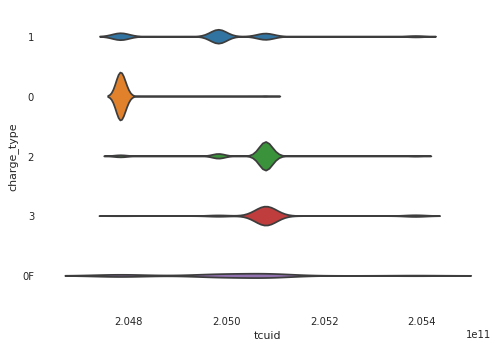

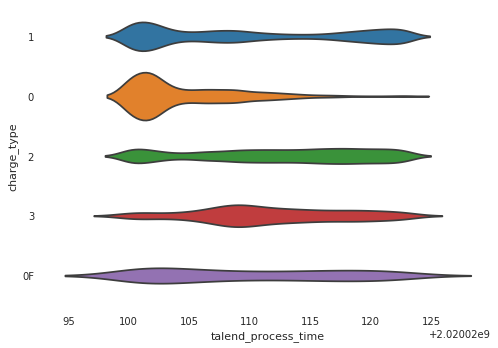

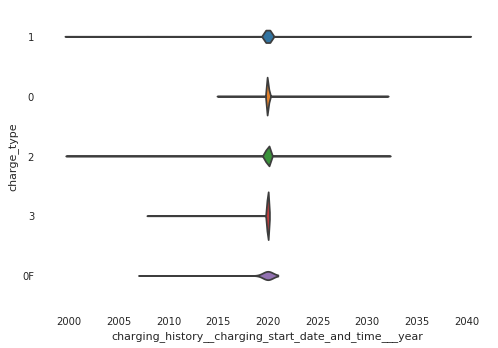

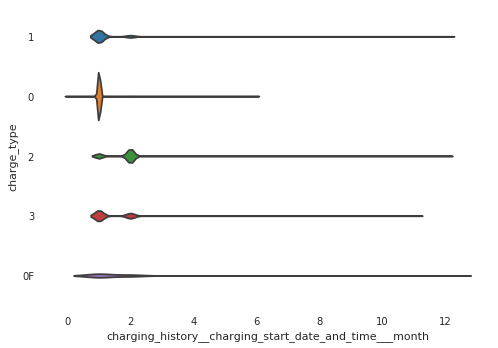

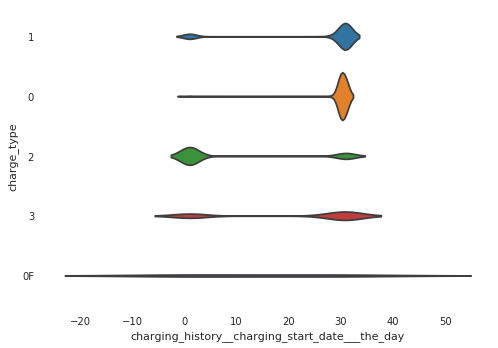

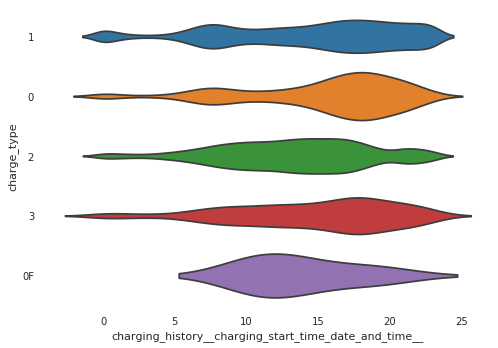

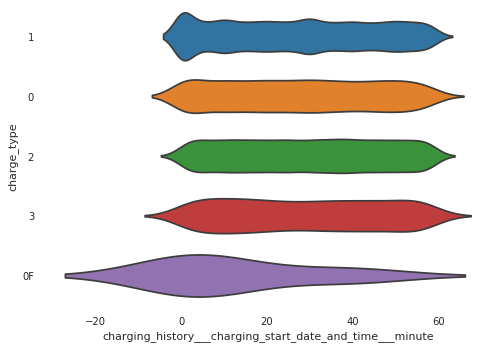

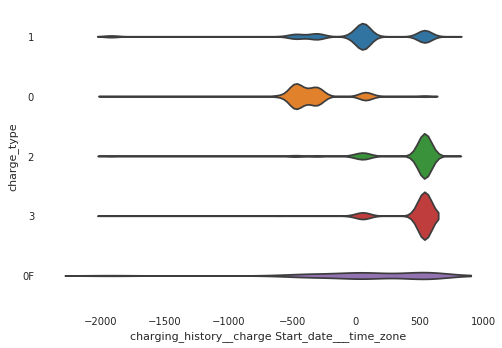

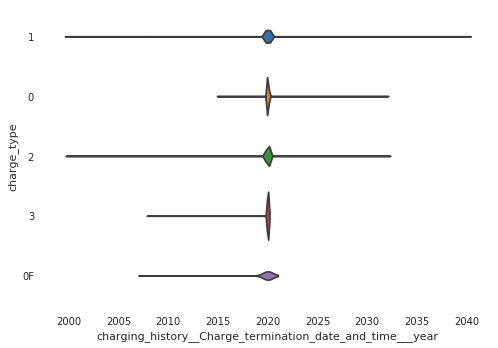

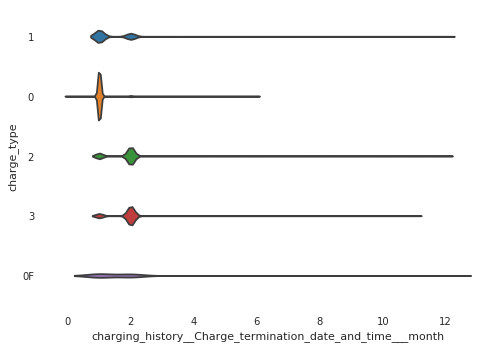

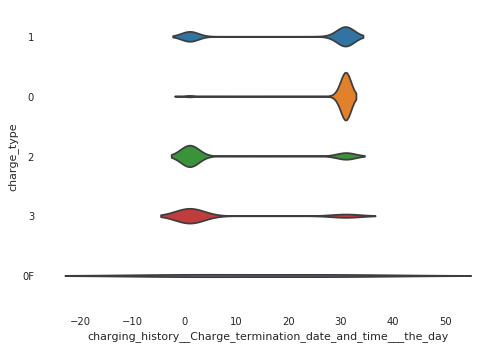

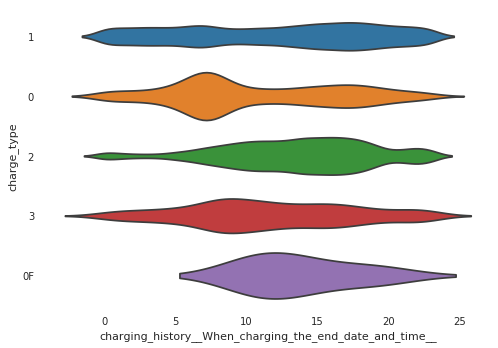

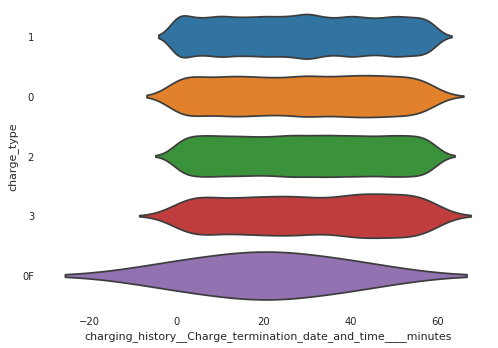

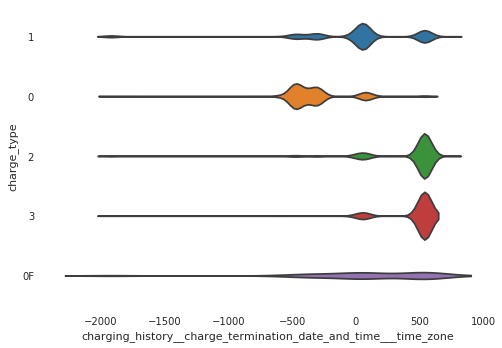

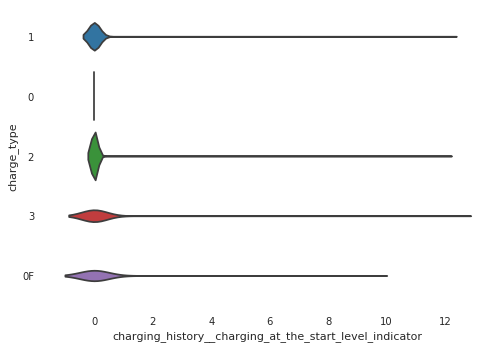

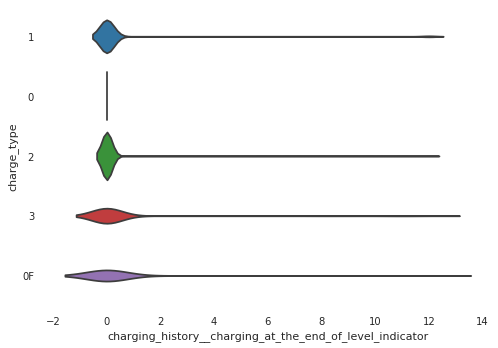

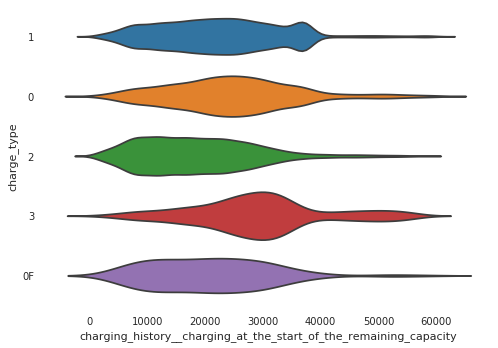

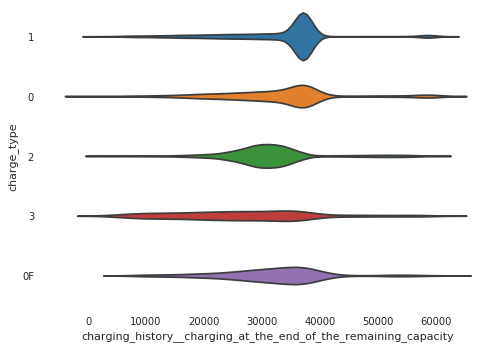

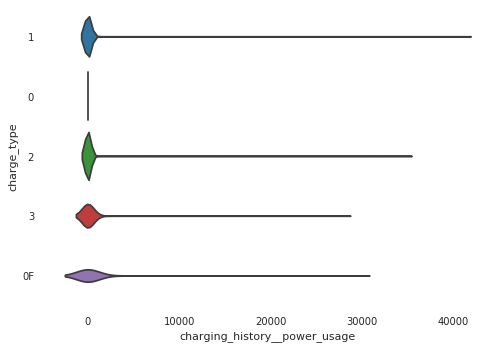

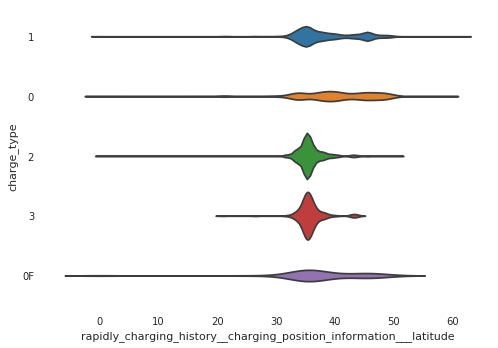

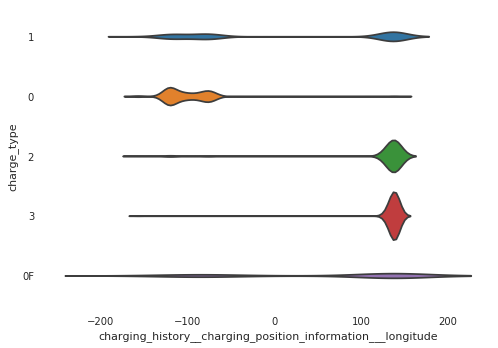

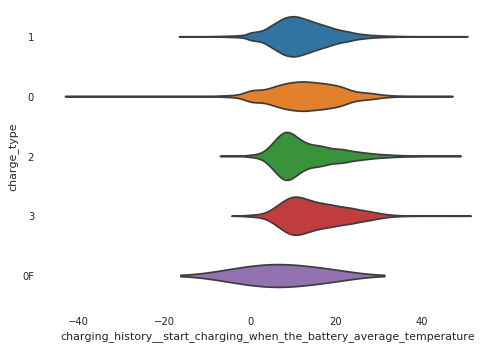

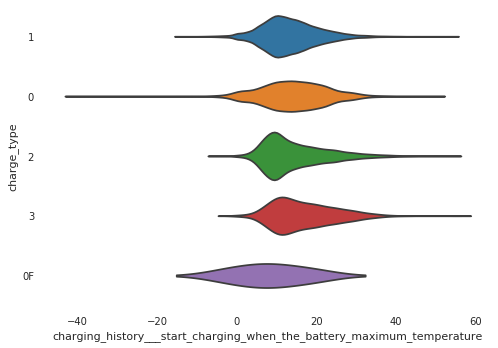

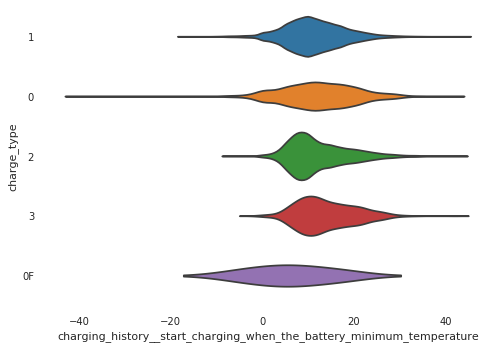

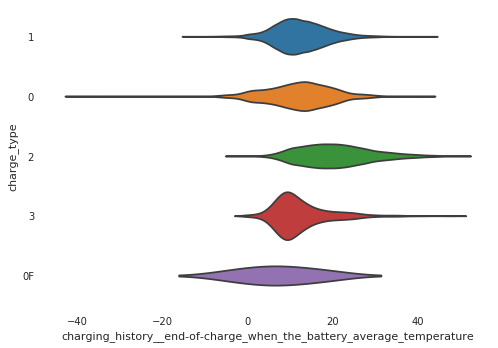

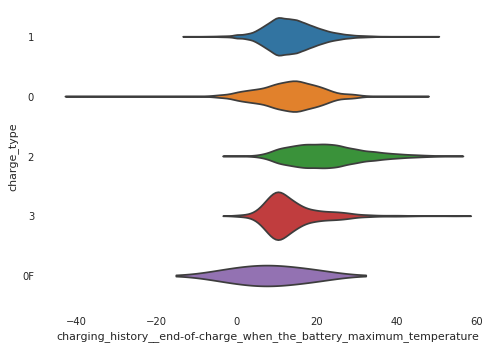

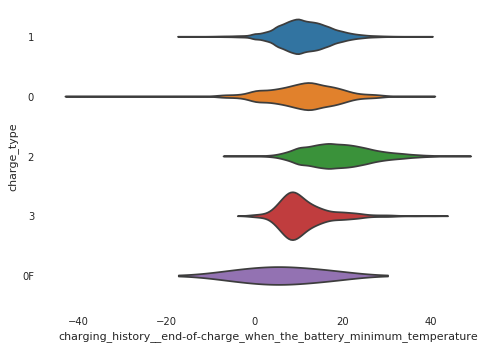

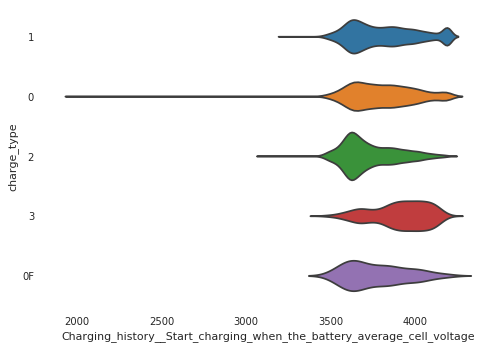

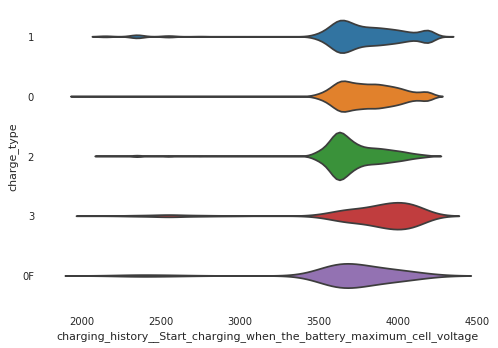

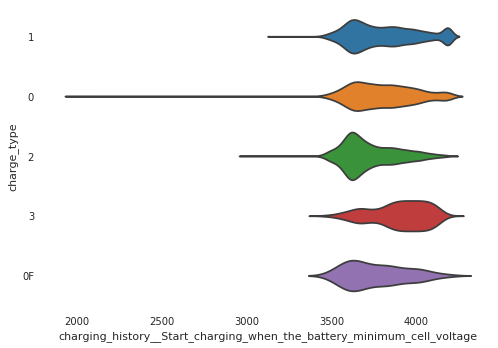

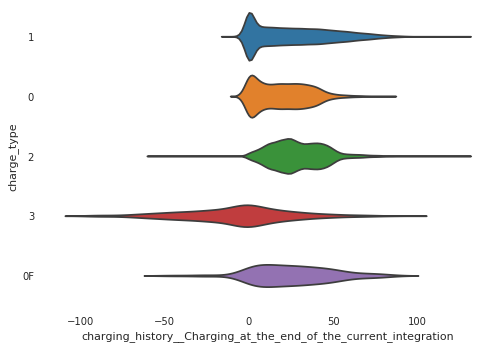

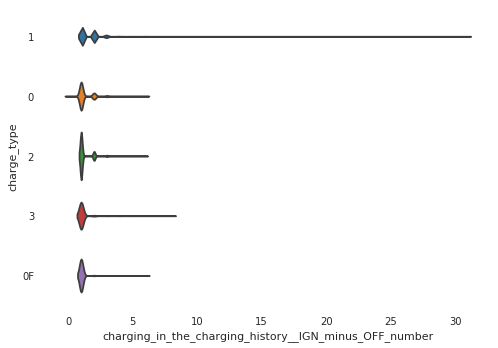

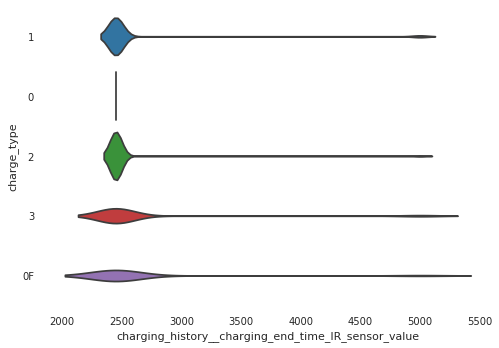

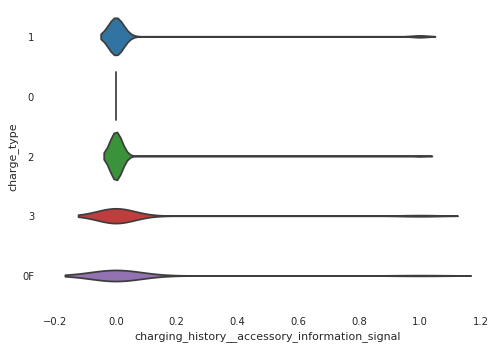

In [8]:

for col in numericalCols:
    sns.violinplot(x=col, y='charge_type', data=df, inner=None)
    #plt.show()
    #sns.swarmplot(x=col, y='charge_type', data=df, color="white", edgecolor="gray")
    plt.show()

## Few observations
  ### Obvious(atleast in hindsight) ones.
     * -- charge_type has almost zero impact/effect on the charging_end_time_IR_sensor_value or charging_history
     * -- Charge_type and minimum_cell_voltage have a good correlation. that's pretty much how charge_type seems defined.
     * -- Same as above for minimum_battery temperature
  #### Interesting:
      * -- Charge type "0F" has a much bigger range of temperatures than the other 3 charge_type(s)
      * -- Charge type "0" is concentrated almost all in the longitude range around -100.. (Hmm.. perhaps local power supply restrictions??)
      * -- Charge type "3" has the most variation in "charging at the end of remaining capacity". perhaps that's the oldest cars and the batteries have weakened enough to have varied capacity??
      
  

/home/nandhini/.virtualenvs/analytics/lib/python3.7/site-packages/seaborn/axisgrid.py:1350: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  fig.tight_layout(pad=layout_pad)


RuntimeError: Selected KDE bandwidth is 0. Cannot estimate density.

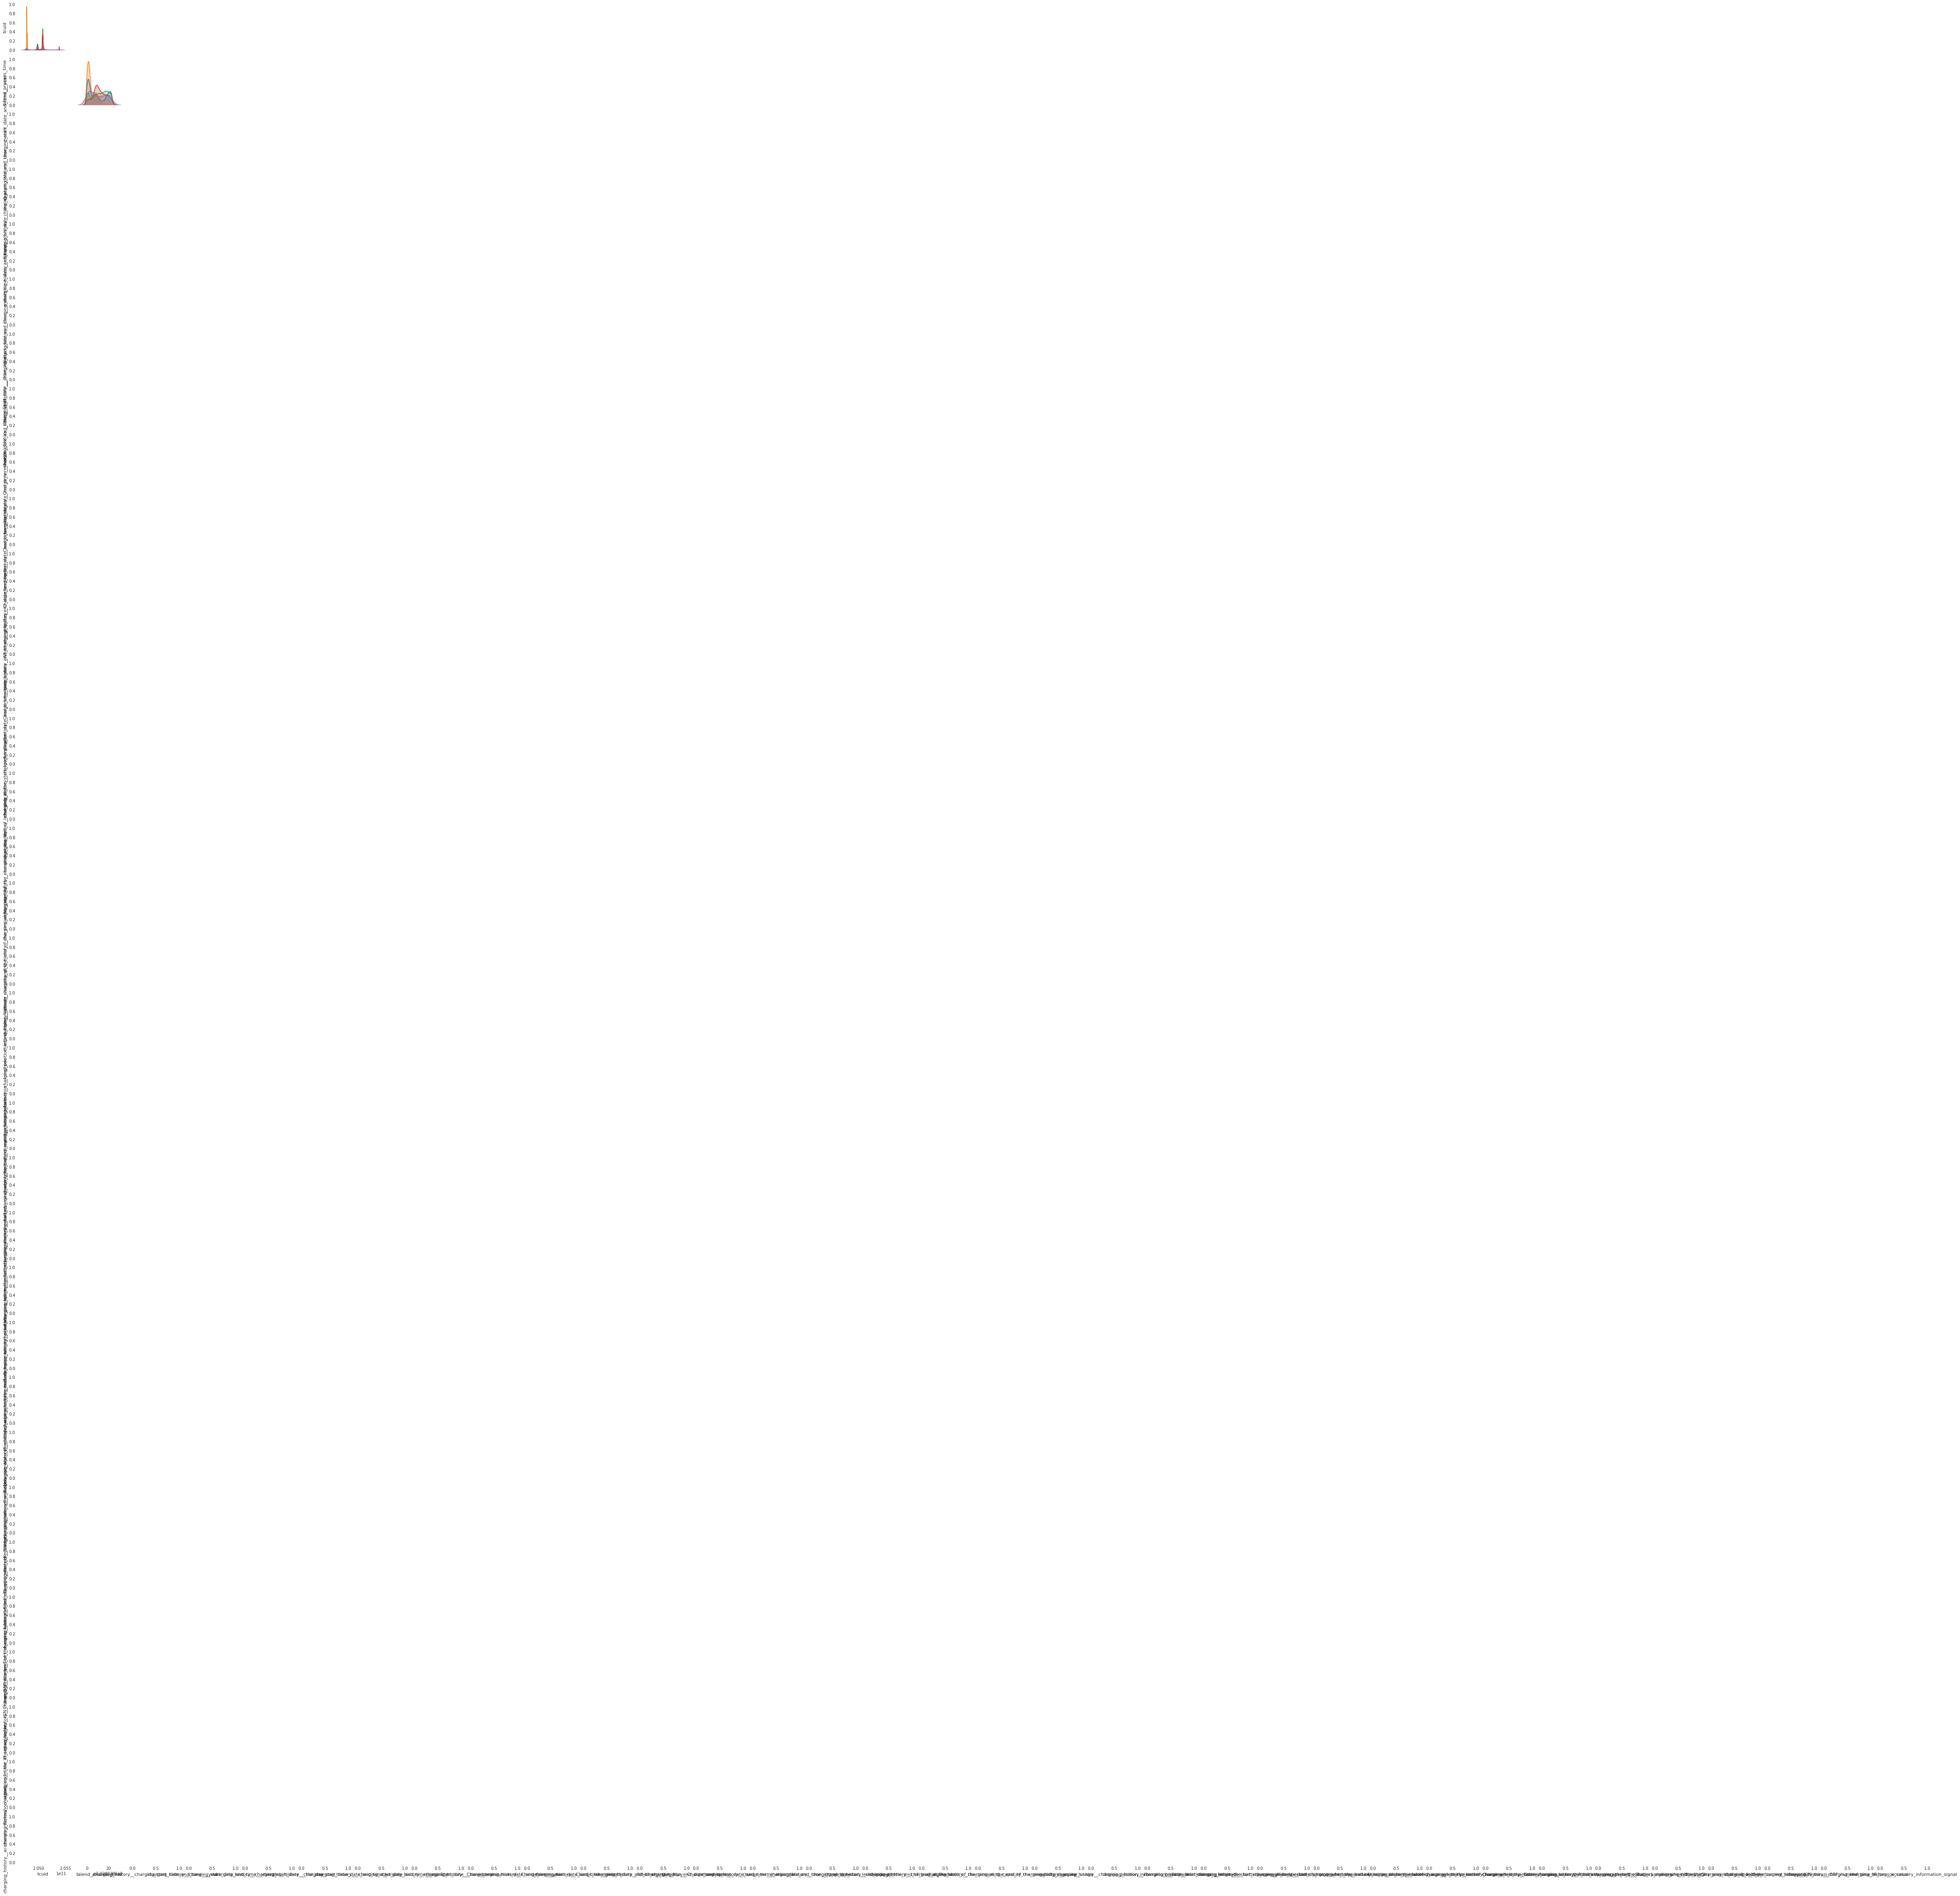

In [9]:
sns.pairplot(df, hue='charge_type')

In [19]:
df.charge_type.unique()

array(['1', '0', '2', '3', '0F'], dtype=object)

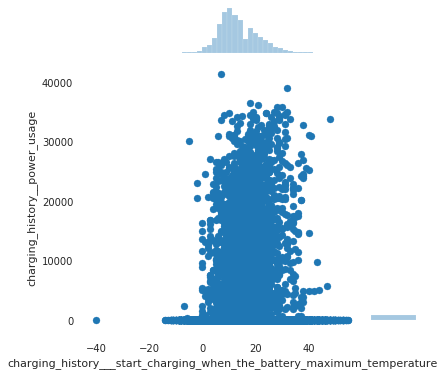

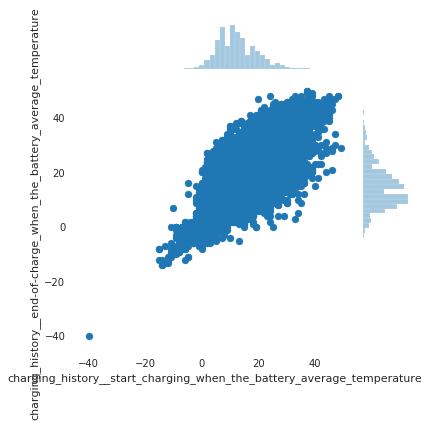

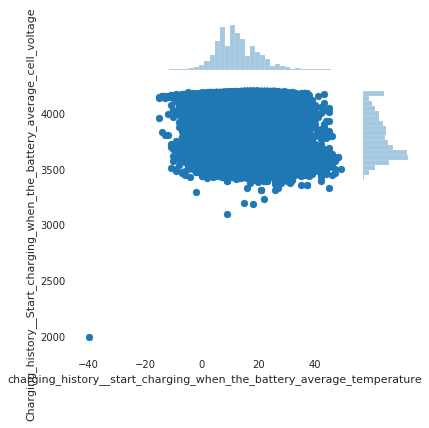

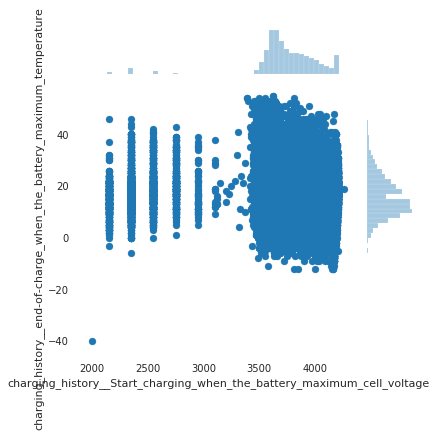

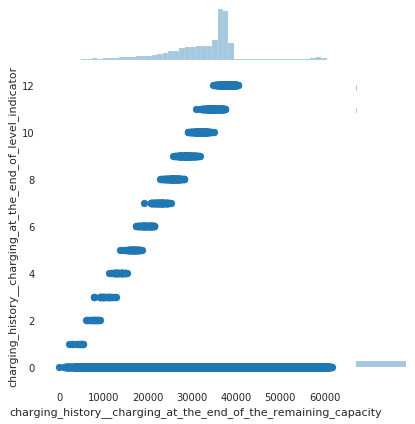

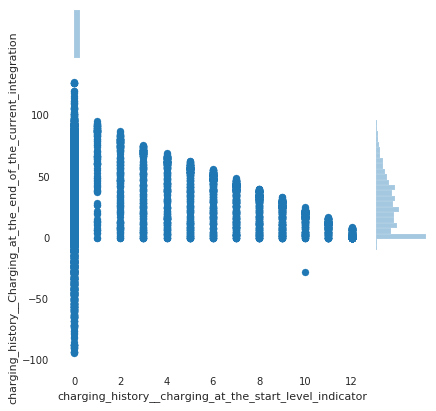

In [18]:
interesting_cols = ['charging_history__charging_at_the_start_level_indicator',
       'charging_history__charging_at_the_end_of_level_indicator',
       'charging_history__charging_at_the_start_of_the_remaining_capacity',
       'charging_history__charging_at_the_end_of_the_remaining_capacity',
       'charging_history__power_usage', 'charge_type',
       'rapidly_charging_history__charging_position_information___latitude',
       'charging_history__charging_position_information___longitude',
       'charging_history__start_charging_when_the_battery_average_temperature',
       'charging_history___start_charging_when_the_battery_maximum_temperature',
       'charging_history__start_charging_when_the_battery_minimum_temperature',
       'charging_history__end-of-charge_when_the_battery_average_temperature',
       'charging_history__end-of-charge_when_the_battery_maximum_temperature',
       'charging_history__end-of-charge_when_the_battery_minimum_temperature',
       'Charging_history__Start_charging_when_the_battery_average_cell_voltage',
       'charging_history__Start_charging_when_the_battery_maximum_cell_voltage',
       'charging_history__Start_charging_when_the_battery_minimum_cell_voltage',
       'charging_history__Charging_at_the_end_of_the_current_integration',
       'charging_in_the_charging_history__IGN_minus_OFF_number',
       'charging_history__charging_end_time_IR_sensor_value',
       'charging_history__accessory_information_signal'
                   ]

with sns.axes_style('white'):
    sns.jointplot(df['charging_history___start_charging_when_the_battery_maximum_temperature'], 
                  df["charging_history__power_usage"],  kind='scatter')
    plt.show()

for each in [('charging_history__start_charging_when_the_battery_average_temperature','charging_history__end-of-charge_when_the_battery_average_temperature'), 
             ('charging_history__start_charging_when_the_battery_average_temperature','Charging_history__Start_charging_when_the_battery_average_cell_voltage'),
             ('charging_history__Start_charging_when_the_battery_maximum_cell_voltage','charging_history__end-of-charge_when_the_battery_maximum_temperature'),
             ('charging_history__charging_at_the_end_of_the_remaining_capacity', 'charging_history__charging_at_the_end_of_level_indicator'),
             ('charging_history__charging_at_the_start_level_indicator','charging_history__Charging_at_the_end_of_the_current_integration'), 
            ]:
    sns.jointplot(each[0], each[1], data=df, kind='scatter')
    plt.show()

In [ ]:
from datetime import datetime
import pytz
def create_start_date_obj(x):
    print(x[4],x[5])
    return datetime(year=int(x[3]), month=int(x[4]),
                    day=int(x[5]), hour=int(x[6]),
                    minute=int(x[7]), tzinfo=pytz.utc)

def create_term_date_obj(x):
    print(x)
    return datetime(year=int(x[10]), month=int(x[11]),
                    day=int(x[12]), hour=int(x[13]),
                    minute=int(x[14]), tzinfo=pytz.utc)


df['charging_start_time'] = df.apply(lambda x: create_start_date_obj(x), axis=1)
df['charging_end_time'] = df.apply(lambda x: create_term_date_obj(x), axis=1)
mod_df.charging_history_charge_start_time_day = mod_df.loc[mod_df.charging_history_charge_start_time_month==2,
        'charging_history_charge_start_time_day'].replace(to_replace=[29, 30,31], value=[28, 28, 28])

mod_df.charging_history_charge_term_time_day = mod_df.loc[mod_df.charging_history_charge_term_time_month==2,
        'charging_history_charge_term_time_day'].replace(to_replace=[29, 30, 31], value=[28,28,28])